In [ ]:
import pathlib as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.integrate import cumulative_trapezoid

DATA_DIR = pl.Path("recorded-data")

paths = {
    "D25":   DATA_DIR / "Log_30.04.2026_09.03.30-25per.txt",
    "D50":   DATA_DIR / "Log_30.04.2026_09.06.16-50per.txt",
    "D75":   DATA_DIR / "Log_30.04.2026_09.09.11-75per.txt",
    "D100":  DATA_DIR / "Log_30.04.2026_09.14.01-100per.txt",
    "pmD25": DATA_DIR / "Log_30.04.2026_09.15.49-pm25per.txt",
}

FSAMPLE_HZ = 500  # from the `fsample=500Hz` header line


def load_log(path: pl.Path) -> pd.DataFrame:
    """Read a Serial.ICE log file (semicolon-separated, first line `fsample=...`)."""
    df = pd.read_csv(path, sep=";", skiprows=1, skipinitialspace=True)
    df.columns = [c.strip() for c in df.columns]
    df["t/s"] = df["Time/ms"] / 1000.0
    return df


dfs = {key: load_log(paths[key]) for key in ("D25", "D50", "D75", "D100")}



division_factor = "25" # tangent through 25% to normalize it

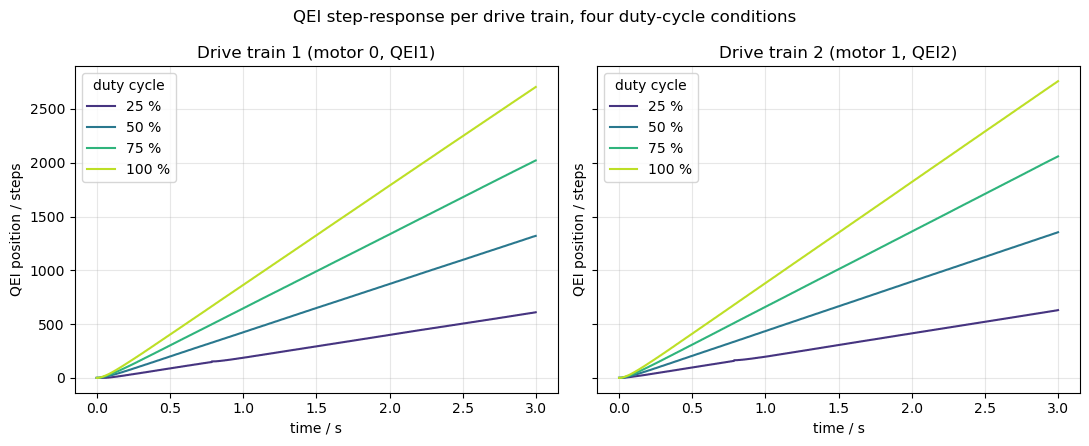

In [9]:
FIG_DIR = pl.Path("../01_RTP-Ausarbeitung/figure")
FIG_DIR.mkdir(parents=True, exist_ok=True)

DRIVES = [("D25", "25 %"), ("D50", "50 %"), ("D75", "75 %"), ("D100", "100 %")]
DRIVE_COLORS = plt.cm.viridis([0.15, 0.4, 0.65, 0.9])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for (key, label), color in zip(DRIVES, DRIVE_COLORS):
    axes[0].plot(dfs[key]["t/s"], dfs[key]["QEI1/steps"], label=label, color=color)
    axes[1].plot(dfs[key]["t/s"], dfs[key]["QEI2/steps"], label=label, color=color)
axes[0].set_title("Drive train 1 (motor 0, QEI1)")
axes[1].set_title("Drive train 2 (motor 1, QEI2)")
for ax in axes:
    ax.set_xlabel("time / s")
    ax.set_ylabel("QEI position / steps")
    ax.grid(True, alpha=0.3)
    ax.legend(title="duty cycle", loc="upper left")
fig.suptitle("QEI step-response per drive train, four duty-cycle conditions")
fig.tight_layout()

fig.savefig(FIG_DIR / "drive-position-comparison.pdf", bbox_inches="tight")
#fig.savefig(FIG_DIR / "drive-position-comparison.png", dpi=200, bbox_inches="tight")
plt.show()